In [20]:
import json
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('..')
from fisheye_camera import CameraCalibrationParameters, cm2pixel
from detection_area import CameraConfiguration, DetectionArea
from geometry import Point

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
with open("../aois.json", 'r') as f:
       aoi_data = json.load(f)

cam4 width = 1880.0, height = 587.0


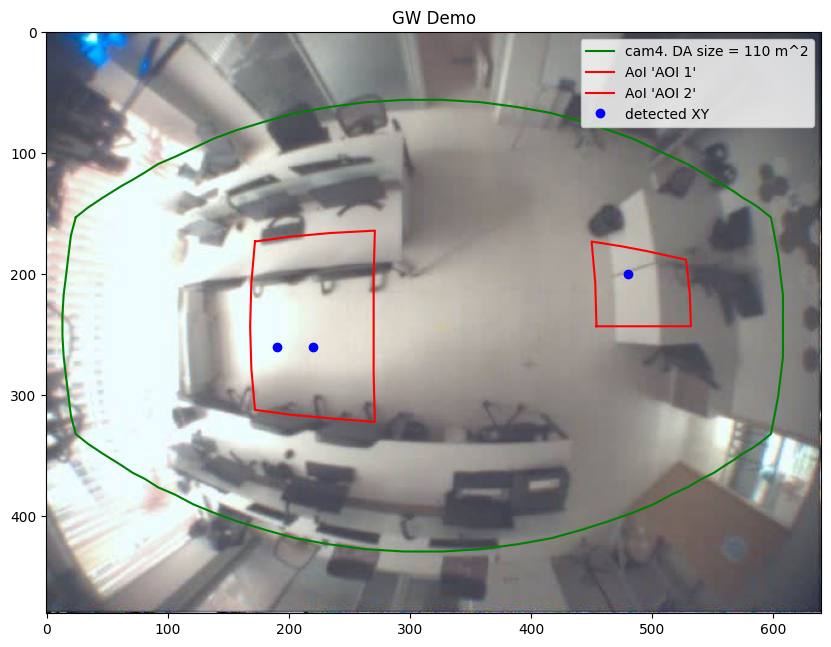

In [32]:
img = cv2.cvtColor(cv2.imread('example.jpg'), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))

H = 270

with open("../camera_calibration/params/pg2-video_20241119142311.json", "rt") as f:
    data = json.load(f)

calibration_params = CameraCalibrationParameters(
    data["LENS_PARAMS"]["CX"],
    data["LENS_PARAMS"]["CY"],
    data["LENS_PARAMS"]["FX"],
    data["LENS_PARAMS"]["FY"],
    data["LENS_PARAMS"]["K0"],
    data["LENS_PARAMS"]["K1"],
    data["LENS_PARAMS"]["K2"],
    data["LENS_PARAMS"]["K3"],
)
 
plt.imshow(img)

cam_config = CameraConfiguration(
    calibration_params,
    data["LENS_PARAMS"]["FOV_X"],
    data["LENS_PARAMS"]["FOV_Y"],
    H,
    data["IMG_W"],
    data["IMG_H"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'g-', label=f"cam4. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

for aoi in aoi_data.values():
    resampled_vertices = da_cam3._resample_polygon(aoi["polygon"][:] + aoi["polygon"][:1])
    vertices_px = [cm2pixel(Point(*v), da_cam3.m_cam.height_cm, 0, da_cam3.m_cam.calibration_params) for v in resampled_vertices]
    vertices_px = np.array([[int(v.x), int(v.y)] for v in vertices_px])
    
    plt.plot(vertices_px[:, 0], vertices_px[:, 1], 'r-', label=f"AoI '{aoi['name']}'")

f = True
for p in [[480, 200], [190, 260], [220, 260]]:
    if f:
        plt.plot(p[0], p[1], 'bo', label="detected XY")
        f = False
    else:
        plt.plot(p[0], p[1], 'bo')

plt.ylim(480, 0)

plt.title("GW Demo")
plt.legend()